## Data Cleaning & Preprocessing

In [6]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [8]:
# Load Dataset
df = pd.read_csv('ecommerce_customer_churn.csv')

In [10]:
df.shape

(3941, 11)

In [9]:
# Top 5 Rows
df.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


In [15]:
# Last 5 Rows
df.tail()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
3936,28.0,9.0,5,Fashion,3,Married,8,0,1.0,231.86,0
3937,8.0,7.0,2,Mobile Phone,2,Single,4,0,4.0,157.80,0
3938,30.0,6.0,5,Laptop & Accessory,3,Married,3,1,2.0,156.60,0
3939,6.0,NaN,4,Mobile,3,Married,10,1,0.0,124.37,1
3940,2.0,7.0,3,Laptop & Accessory,5,Married,1,0,2.0,153.73,0


In [13]:
# columns in a Dataset
df.columns

Index(['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered',
       'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus',
       'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount',
       'Churn'],
      dtype='str')

In [20]:
# Correct Categorical inconsistencies
df['PreferedOrderCat'] = df['PreferedOrderCat'].replace({'Mobile' : 'Mobile Phone'})

In [21]:
# Handling missing values
df.isnull().sum()

Tenure                      194
WarehouseToHome             169
NumberOfDeviceRegistered      0
PreferedOrderCat              0
SatisfactionScore             0
MaritalStatus                 0
NumberOfAddress               0
Complain                      0
DaySinceLastOrder           213
CashbackAmount                0
Churn                         0
dtype: int64

In [30]:
df['Tenure'] = df['Tenure'].fillna(df['Tenure'].median())
df['WarehouseToHome'] = df['WarehouseToHome'].fillna(df['WarehouseToHome'].mean())
df['DaySinceLastOrder'] = df['DaySinceLastOrder'].fillna(df['DaySinceLastOrder'].mean())


In [31]:
df.isnull().sum()

Tenure                      0
WarehouseToHome             0
NumberOfDeviceRegistered    0
PreferedOrderCat            0
SatisfactionScore           0
MaritalStatus               0
NumberOfAddress             0
Complain                    0
DaySinceLastOrder           0
CashbackAmount              0
Churn                       0
dtype: int64

In [32]:
# Encode Categorical Variables
df_encoded = pd.get_dummies(df, columns=['PreferedOrderCat','MaritalStatus'], drop_first=True)

In [34]:
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [36]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Exploratory Data Analysis

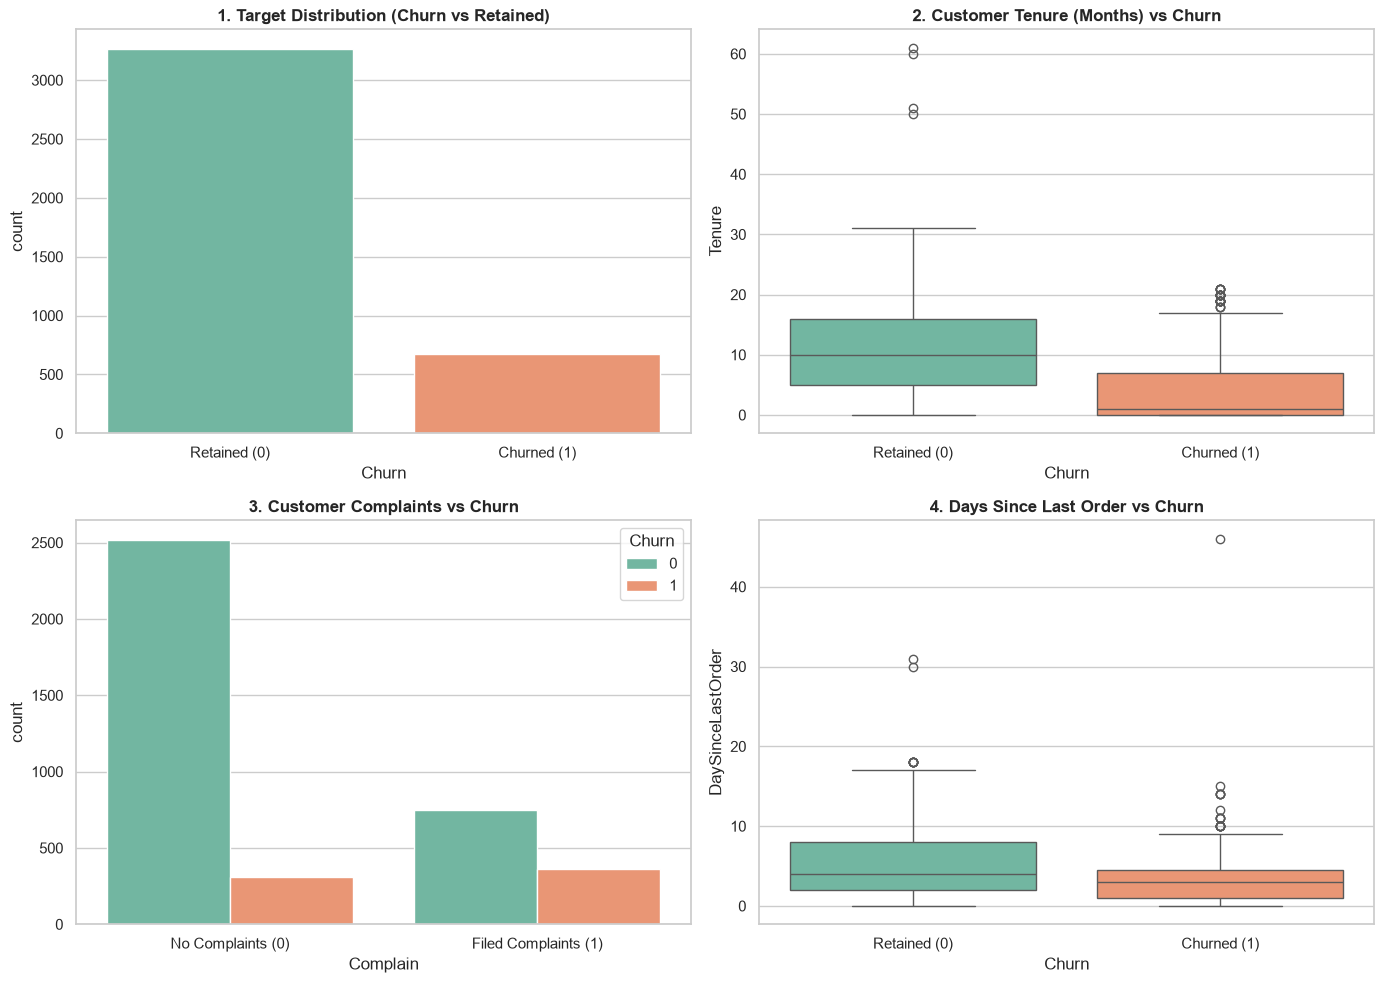

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style='whitegrid')

# 1. Key Feature Visualizations Matrix
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Target Class Imbalance
sns.countplot(data=df, x='Churn', hue='Churn', ax=axes[0, 0], palette='Set2', legend=False)
axes[0, 0].set_title('1. Target Distribution (Churn vs Retained)', fontsize=12, fontweight='bold')
axes[0, 0].set_xticks([0, 1])
axes[0, 0].set_xticklabels(['Retained (0)', 'Churned (1)'])

# Tenure vs Churn
sns.boxplot(data=df, x='Churn', y='Tenure', hue='Churn', ax=axes[0, 1], palette='Set2', legend=False)
axes[0, 1].set_title('2. Customer Tenure (Months) vs Churn', fontsize=12, fontweight='bold')
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(['Retained (0)', 'Churned (1)'])

# Complaints vs Churn
sns.countplot(data=df, x='Complain', hue='Churn', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('3. Customer Complaints vs Churn', fontsize=12, fontweight='bold')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['No Complaints (0)', 'Filed Complaints (1)'])

# Days Since Last Order vs Churn
sns.boxplot(data=df, x='Churn', y='DaySinceLastOrder', hue='Churn', ax=axes[1, 1], palette='Set2', legend=False)
axes[1, 1].set_title('4. Days Since Last Order vs Churn', fontsize=12, fontweight='bold')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['Retained (0)', 'Churned (1)'])

plt.tight_layout()
plt.show()

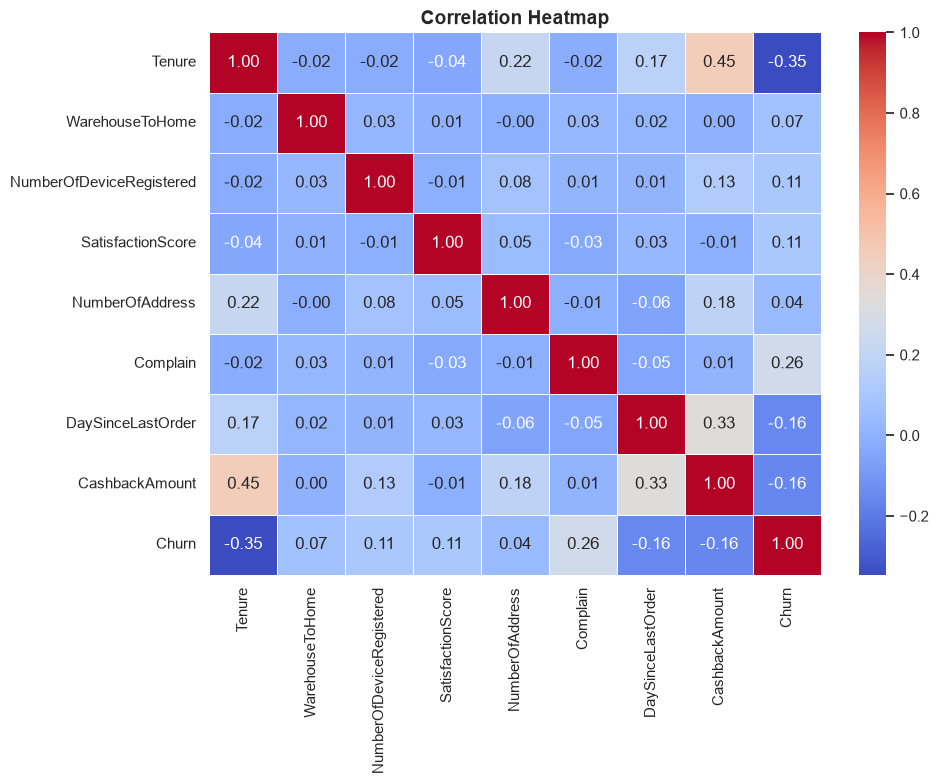

In [51]:
plt.figure(figsize=(10,8))
numeric_df = df.select_dtypes(include=['float64','int64'])
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=14,fontweight='bold')
plt.tight_layout()
plt.show()

## Model Training & Evaluation

In [65]:
# Machine Learning Models Import
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Import Evaluation Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Initialize Models Dictionary
models = {
    'Logistic Regression' : LogisticRegression(random_state=42, class_weight='balanced'),
    'Decision Tree' : DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    'Random Forest' : RandomForestClassifier(random_state=42, class_weight='balanced'),
    'KNN' : KNeighborsClassifier(),
    'Naive Bayes' : GaussianNB(),
    'SVM' : SVC(probability=True, random_state=42, class_weight='balanced')
}

results = []

# Loop to Train, Predict & Evaluate each Model
for name, model in models.items():
    # 1. Fit/Train the Model
    model.fit(X_train_scaled, y_train)

    # 2. Predict on Test Set
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]if hasattr(model, 'predict_proba') else None
    

    # 3. calculate Performance Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 0.0

    # Store Metrics in List
    results.append({
        'Model' : name,
        'Accuracy' : round(acc, 4),
        'Precision' : round(prec, 4),
        'Recall' : round(rec, 4),
        'F1-Score' : round(f1, 4),
        'Roc-AUC' : round(auc, 4)
    })

# Convert Results to DataFrame and Sort by Recall (Key Metric for Churn)
results_df = pd.DataFrame(results).sort_values(by='Recall', ascending=False)
display(results_df)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-Score,Roc-AUC
2,Random Forest,0.9354,0.7917,0.8444,0.8172,0.9666
5,SVM,0.8542,0.5490,0.8296,0.6608,0.9179
0,Logistic Regression,0.8010,0.4542,0.8074,0.5813,0.8756
1,Decision Tree,0.9303,0.8175,0.7630,0.7893,0.8639
4,Naive Bayes,0.7376,0.3647,0.7185,0.4838,0.8118
3,KNN,0.8910,0.7952,0.4889,0.6055,0.9013


## Visualizing Confusion Matrix & Feature Importance

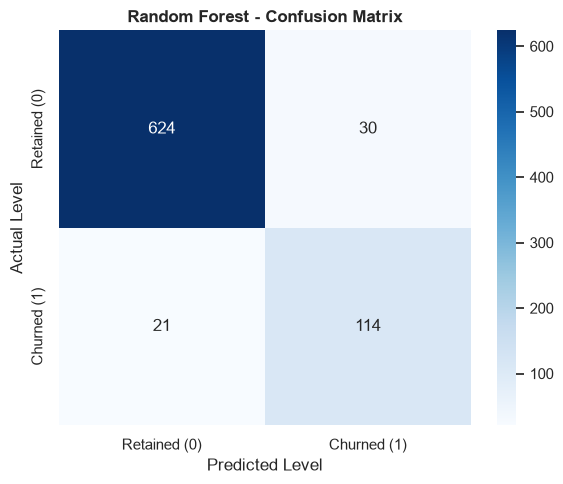

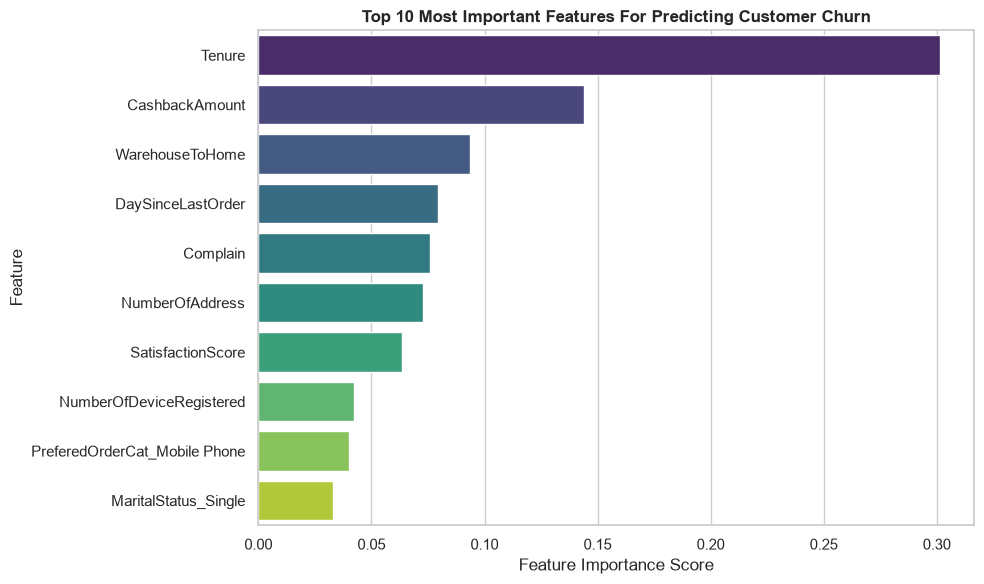

In [64]:
from sklearn.metrics import confusion_matrix

# 1. Best Model (Random Forest) Confusion Matrix Plot
best_model = models['Random Forest']
y_pred_rf = best_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
           xticklabels = ['Retained (0)', 'Churned (1)'],
           yticklabels = ['Retained (0)', 'Churned (1)'])
plt.title('Random Forest - Confusion Matrix', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Level')
plt.ylabel('Actual Level')
plt.tight_layout()
plt.show()

# 2. Feature Importance Plot (What Factors decide Churn)
importances = best_model.feature_importances_
feature_names = X.columns
feature_df = pd.DataFrame({'Feature' : feature_names, 'Importance' : importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_df.head(10), x='Importance', y='Feature', hue='Feature', palette='viridis', legend=False)
plt.title('Top 10 Most Important Features For Predicting Customer Churn', fontsize=12, fontweight='bold')
plt.xlabel('Feature Importance Score')
plt.tight_layout()
plt.show()

## Project Conclusion & Business Recommendations

1. **Model Performance:** Random Forest achieved the highest Recall (~84.4%) and ROC-AUC score (~0.966), making it the optimal decision-support model for identifying at-risk customers.
2. **Key Retention Drivers:** The primary behaviors signaling churn are low **Tenure**, reduced **Cashback Rewards**, longer **Delivery Distances**, and active **Customer Complaints**.
3. **Actionable Business Strategy:** 
   - Target new customers (Tenure < 6 months) with onboarding offers and feedback loops.
   - Prioritize quick issue resolution for customers filing complaints to prevent churn.
   - Offer customized cashback incentives to inactive users showing high `DaySinceLastOrder`.